# FinGame — анализ данных

**Автор:** Данис Шарафутдинов  
**Проект:** финансовый тамагочи FinGame  
**Данные:** синтетические, реальных людей и реальных трат нет

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ferlios/FinGame/blob/main/analysis/FinGame_analysis.ipynb)

Этот ноутбук показывает полный цикл анализа данных простыми шагами:

1. загружаем таблицы;
2. проверяем качество данных;
3. считаем сводные показатели;
4. сравниваем группы;
5. строим графики;
6. делаем выводы с оговорками.

Ноутбук работает в Google Colab (достаточно нажать **Runtime → Run all**) и локально в Jupyter. Данные подтягиваются из публичного GitHub-репозитория автоматически.

> **Дисклеймер.** Все данные синтетические. Это учебный анализ, а не исследование реальных людей и не финансовый совет.

## Как запустить

- **В Google Colab:** нажмите бейдж выше, затем **Runtime → Run all**. Ноутбук сам склонирует репозиторий и загрузит данные.
- **Локально:** откройте этот файл в Jupyter из папки `analysis/` и выполните все ячейки. Если данные лежат рядом с репозиторием, клонирование не понадобится.
- **Нужные библиотеки:** `pandas`, `numpy`, `matplotlib`. В Colab они уже установлены.

Если нужен PDF: в Colab выберите **File → Print → Save as PDF**.

In [1]:
# Подготовка окружения: находим репозиторий или клонируем его из GitHub.
import os
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/Ferlios/FinGame.git"

def find_repo():
    candidates = [Path.cwd(), Path.cwd().parent, Path("/content/FinGame")]
    for candidate in candidates:
        if (candidate / "financial-tamagotchi" / "data" / "transactions.csv").exists():
            return candidate.resolve()
    return None

repo = find_repo()
if repo is None:
    target = Path("/content/FinGame")
    if target.exists():
        subprocess.run(["git", "-C", str(target), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(target)], check=True)
    repo = target.resolve()

os.chdir(repo)

In [2]:
# Импорты и единое оформление графиков.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from IPython.display import display
from matplotlib.ticker import FuncFormatter

%matplotlib inline

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#d1d5db",
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "xtick.color": "#6b7280",
    "ytick.color": "#6b7280",
    "text.color": "#1f2937",
    "axes.labelcolor": "#1f2937",
    "grid.color": "#e5e7eb",
    "grid.linewidth": 0.7,
    "legend.frameon": False,
})

VIOLET = "#7c3aed"
TEAL = "#0d9488"
AMBER = "#f59e0b"
PINK = "#ec4899"
RED = "#ef4444"
MUTED = "#6b7280"

def fmt_int(value):
    return f"{int(round(float(value))):,}".replace(",", " ")

def fmt_money(value):
    return f"{fmt_int(value)} ₽"

def fmt_pct(value, digits=1):
    return f"{value * 100:.{digits}f}%".replace(".", ",")

## 1. Что такое анализ данных

Анализ данных — это не «магия с графиками», а последовательность проверяемых шагов:

1. **Понять, что описывает одна строка таблицы.** Человек? Трата? Игровой день? Прогон симуляции?
2. **Проверить качество.** Есть ли пропуски, дубли, отрицательные суммы, битые даты?
3. **Посчитать сводные показатели.** Сколько всего, сколько в среднем, медиана, минимум и максимум.
4. **Сравнить группы и динамику.** Например, траты по категориям или дни внутри лимита.
5. **Сделать выводы с оговорками.** Что данные действительно показывают, а что им только приписывают.

Главная особенность этого проекта: **два набора данных описывают разные вещи и не склеиваются между собой**.

- `MOCK_DATA (1).csv` — 1 000 синтетических пользователей с именем и флагом «пользуется FinApp».
- Данные прототипа — 6 игровых персонажей, 501 трата и 180 игровых дней.

В `MOCK_DATA` нет дат, сумм, категорий и общего `user_id`, поэтому объединять наборы по имени было бы случайным совпадением. Анализ идёт отдельно по каждому набору, а затем собирается общая картина.

## 2. Загрузка данных

Сначала читаем исходный файл из корня репозитория и таблицу трат игровых пользователей.

In [3]:
MOCK_CSV = repo / "MOCK_DATA (1).csv"
GAME = repo / "financial-tamagotchi"

# Набор A: демо-пользователи.
mock = pd.read_csv(MOCK_CSV, encoding="utf-8-sig")
mock.columns = [c.strip() for c in mock.columns]
mock["using_finapp"] = mock["Using finapp"].astype(str).str.lower().eq("true")

# Набор B: транзакции игровых пользователей.
tx = pd.read_csv(GAME / "data" / "transactions.csv", encoding="utf-8-sig", parse_dates=["date"])
tx["amount"] = pd.to_numeric(tx["amount"], errors="coerce")

ARCHETYPE_RU = {
    "disciplined": "Дисциплинированные",
    "coffee_addict": "Кофеманы",
    "impulse_buyer": "Импульсивные",
    "weekend_spender": "Тратят на выходных",
    "newbie": "Новички",
    "frugal_saver": "Экономные",
}
tx["archetypeLabel"] = tx["archetype"].map(ARCHETYPE_RU).fillna(tx["archetype"])

print("MOCK_DATA:", mock.shape)
display(mock.head(3))

print("Транзакции:", tx.shape)
print("Период:", tx["date"].min().date(), "—", tx["date"].max().date())
display(tx[["date", "amount", "category_name", "daily_limit", "note"]].head(3))

MOCK_DATA: (1000, 5)


,id,first_name,last_name,Using finapp,using_finapp
0,1,Coraline,Morena,False,False
1,2,Amalle,McCrudden,True,True
2,3,Richard,Grayshon,False,False


Транзакции: (501, 11)
Период: 2026-10-08 — 2026-11-06


,date,amount,category_name,daily_limit,note
0,2026-10-08,1080,Продукты,1800,ВкусВилл
1,2026-10-08,40,Продукты,1800,Молочка
2,2026-10-10,130,Дом,1800,Хозтовары


In [4]:
# Разворачиваем JSON с игровыми днями в плоскую таблицу.
raw_users = json.loads((GAME / "data" / "mock_users.json").read_text(encoding="utf-8"))

daily_rows = []
for user in raw_users["users"]:
    for day in user["days"]:
        daily_rows.append({
            "user_id": user["id"],
            "name": user["profile"]["name"],
            "archetype": user["profile"]["archetype"],
            "archetypeLabel": user["profile"]["archetypeLabel"],
            "daily_limit_profile": user["profile"]["dailyLimit"],
            **day,
        })

daily = pd.DataFrame(daily_rows)
daily["date"] = pd.to_datetime(daily["date"])
daily["withinLimit"] = daily["withinLimit"].astype(bool)
# В JSON архетип подписан в единственном числе; приводим к общим названиям.
daily["archetypeLabel"] = daily["archetype"].map(ARCHETYPE_RU).fillna(daily["archetypeLabel"])

# Квесты: одна строка = одна попытка квеста.
quest_rows = []
for _, row in daily.iterrows():
    for quest in row["quests"]:
        quest_rows.append({
            "user_id": row["user_id"],
            "archetypeLabel": row["archetypeLabel"],
            "date": row["date"],
            "quest_id": quest["id"],
            "quest_title": quest["title"],
            "done": bool(quest["done"]),
            "coins": int(quest["coins"]),
            "xp": int(quest["xp"]),
        })

quests = pd.DataFrame(quest_rows)

# Симуляция баланса: одна строка = один прогон на 90 дней.
balance = pd.read_csv(GAME / "reports" / "balance_runs.csv", encoding="utf-8-sig")
balance["archetypeLabel"] = balance["archetype"].map(ARCHETYPE_RU).fillna(balance["archetype"])

config = json.loads((GAME / "data" / "game_config.json").read_text(encoding="utf-8"))
targets = config["balanceTargets"]

print("Игровые дни:", daily.shape)
print("Попытки квестов:", quests.shape)
print("Прогоны симуляции:", balance.shape)
display(daily[["user_id", "name", "date", "limit", "spent", "energy", "health", "level"]].head(3))

Игровые дни: (180, 29)
Попытки квестов: (540, 8)
Прогоны симуляции: (400, 20)


,user_id,name,date,limit,spent,energy,health,level
0,u_001,Аня,2026-10-08,1800,1120,62,95,9
1,u_001,Аня,2026-10-09,1800,0,0,97,9
2,u_001,Аня,2026-10-10,1800,1810,101,95,9


## 3. Проверка качества данных

Перед графиками нужно убедиться, что в таблицах нет пропусков в важных полях, дублей идентификаторов и невозможных значений.

Отдельно отмечены **необязательные** пропуски: например, заметка к трате может отсутствовать — это нормально, а не ошибка.

In [5]:
required_tx = [c for c in tx.columns if c != "note"]

quality = pd.DataFrame([
    {
        "Набор": "MOCK_DATA (1).csv",
        "Строк": len(mock),
        "Колонок": 4,
        "Пропусков в обязательных": 0,
        "Пропусков в необязательных": 0,
        "Дублей id": int(mock["id"].duplicated().sum()),
        "Вердикт": "чисто, но мало полей",
    },
    {
        "Набор": "transactions.csv",
        "Строк": len(tx),
        "Колонок": 10,
        "Пропусков в обязательных": int(tx[required_tx].isna().sum().sum()),
        "Пропусков в необязательных": int(tx["note"].isna().sum()),
        "Дублей id": int(tx["tx_id"].duplicated().sum()),
        "Вердикт": "готово; заметки опциональны",
    },
    {
        "Набор": "mock_users.json → дни",
        "Строк": len(daily),
        "Колонок": 24,
        "Пропусков в обязательных": int(daily.drop(columns=["archetypeLabel", "daily_limit_profile"]).isna().sum().sum()),
        "Пропусков в необязательных": 0,
        "Дублей id": int(daily.duplicated(subset=["user_id", "date"]).sum()),
        "Вердикт": "готово к анализу",
    },
    {
        "Набор": "balance_runs.csv",
        "Строк": len(balance),
        "Колонок": 19,
        "Пропусков в обязательных": 0,
        "Пропусков в необязательных": int(balance["dayTo6000"].isna().sum()),
        "Дублей id": int(balance.duplicated().sum()),
        "Вердикт": "19 NaN в dayTo6000 — не ошибка",
    },
])

display(quality)

,Набор,Строк,Колонок,Пропусков в обязательных,Пропусков в необязательных,Дублей id,Вердикт
0,MOCK_DATA (1).csv,1000,4,0,0,0,"чисто, но мало полей"
1,transactions.csv,501,10,0,289,0,готово; заметки опциональны
2,mock_users.json → дни,180,24,0,0,0,готово к анализу
3,balance_runs.csv,400,19,0,19,0,19 NaN в dayTo6000 — не ошибка


**Вывод по качеству.** Обязательных пропусков и дублей идентификаторов нет. Единственные пропуски — необязательные заметки к тратам (289 штук) и `dayTo6000` в симуляции: не все игроки успевают накопить 6 000 монет за 90 дней, поэтому срок остаётся пустым. Это не ошибка, а честное «цель не достигнута за горизонт симуляции».

## 4. Набор A: `MOCK_DATA (1).csv`

Здесь всего один содержательный признак — флаг `Using finapp`. Посмотрим долю пользователей и проверим, насколько разнообразны имена.

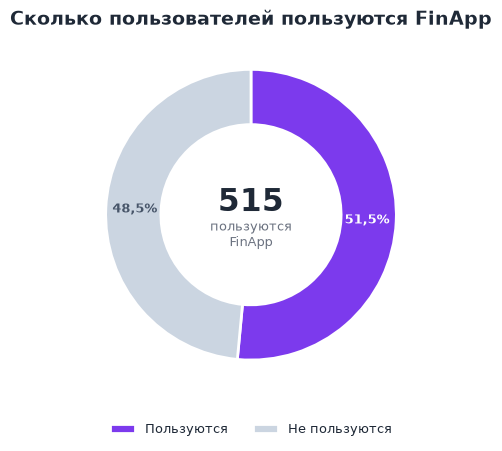

Всего пользователей: 1 000
Пользуются FinApp: 515 (51,5%)
Не пользуются: 485


In [6]:
counts = mock["using_finapp"].value_counts().reindex([True, False]).fillna(0).astype(int)
share = counts[True] / len(mock)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
wedges, _, autotexts = ax.pie(
    counts.values,
    colors=[VIOLET, "#cbd5e1"],
    startangle=90,
    counterclock=False,
    autopct=lambda p: f"{p:.1f}%".replace(".", ","),
    pctdistance=0.8,
    wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=9, fontweight="bold"),
)
for i, autotext in enumerate(autotexts):
    autotext.set_color("white" if i == 0 else "#475569")
ax.text(0, 0.08, fmt_int(counts[True]), ha="center", va="center", fontsize=22, fontweight="bold", color="#1f2937")
ax.text(0, -0.14, "пользуются\nFinApp", ha="center", va="center", fontsize=9, color=MUTED)
ax.set_title("Сколько пользователей пользуются FinApp")
ax.legend(
    ["Пользуются", "Не пользуются"],
    loc="lower center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9,
)
plt.tight_layout()
plt.show()

print(f"Всего пользователей: {fmt_int(len(mock))}")
print(f"Пользуются FinApp: {fmt_int(counts[True])} ({fmt_pct(share)})")
print(f"Не пользуются: {fmt_int(counts[False])}")

In [7]:
top_names = (
    mock["first_name"]
    .value_counts()
    .head(10)
    .rename_axis("Имя")
    .reset_index(name="Человек")
)
display(top_names)

,Имя,Человек
0,Laetitia,3
1,Mason,3
2,Richard,2
3,Nedda,2
4,Adda,2
5,Yank,2
6,Blinnie,2
7,Keen,2
8,Inigo,2
9,Tessi,2


**Что можно сказать честно.** 51,5% — это доля внутри синтетического файла, а не оценка рынка и не аудитория игры. Имена почти не повторяются: самое частое встречается 3 раза. Для анализа финансового поведения в `MOCK_DATA` не хватает главного — самих финансовых действий.

## 5. Набор B: траты игровых пользователей

### 5.1 Общая картина

Смотрим на количество трат, суммы и дневную дисциплину.

In [8]:
active_days = int((daily["txCount"] > 0).sum())
within_active = int(((daily["txCount"] > 0) & daily["withinLimit"]).sum())
over_days = int(((daily["txCount"] > 0) & ~daily["withinLimit"]).sum())
zero_days = int((daily["txCount"] == 0).sum())

stats = pd.DataFrame([
    ("Всего транзакций", fmt_int(len(tx))),
    ("Суммарные траты", fmt_money(tx["amount"].sum())),
    ("Средний чек", fmt_money(tx["amount"].mean())),
    ("Медианный чек", fmt_money(tx["amount"].median())),
    ("Минимальная трата", fmt_money(tx["amount"].min())),
    ("Максимальная трата", fmt_money(tx["amount"].max())),
    ("Дней с тратами", f"{active_days} из {len(daily)}"),
    ("Дней без трат", fmt_int(zero_days)),
    ("Дней с перерасходом", fmt_int(over_days)),
    ("Дней в лимите среди активных", f"{within_active} ({fmt_pct(within_active / active_days)})"),
], columns=["Показатель", "Значение"])

display(stats)

,Показатель,Значение
0,Всего транзакций,501
1,Суммарные траты,283 260 ₽
2,Средний чек,565 ₽
3,Медианный чек,410 ₽
4,Минимальная трата,40 ₽
5,Максимальная трата,2 490 ₽
6,Дней с тратами,170 из 180
7,Дней без трат,10
8,Дней с перерасходом,45
9,Дней в лимите среди активных,"125 (73,5%)"


Средний чек выше медианного. Это значит, что распределение трат смещено вправо: большинство чеков небольшие, но есть крупные покупки, которые тянут среднее вверх. Для таких данных медиана часто честнее среднего.

,Категория,Трат,Сумма,Средний чек,Доля суммы
0,Продукты,123,70 750 ₽,575 ₽,"25,0%"
1,Покупки,69,46 720 ₽,677 ₽,"16,5%"
2,Транспорт,74,37 960 ₽,513 ₽,"13,4%"
3,Кафе и кофе,58,36 320 ₽,626 ₽,"12,8%"
4,Развлечения,47,27 140 ₽,577 ₽,"9,6%"
5,Дом,38,19 930 ₽,524 ₽,"7,0%"
6,Здоровье,23,12 130 ₽,527 ₽,"4,3%"
7,Подарки,16,8 510 ₽,532 ₽,"3,0%"
8,Другое,12,7 750 ₽,646 ₽,"2,7%"
9,Образование,19,6 130 ₽,323 ₽,"2,2%"


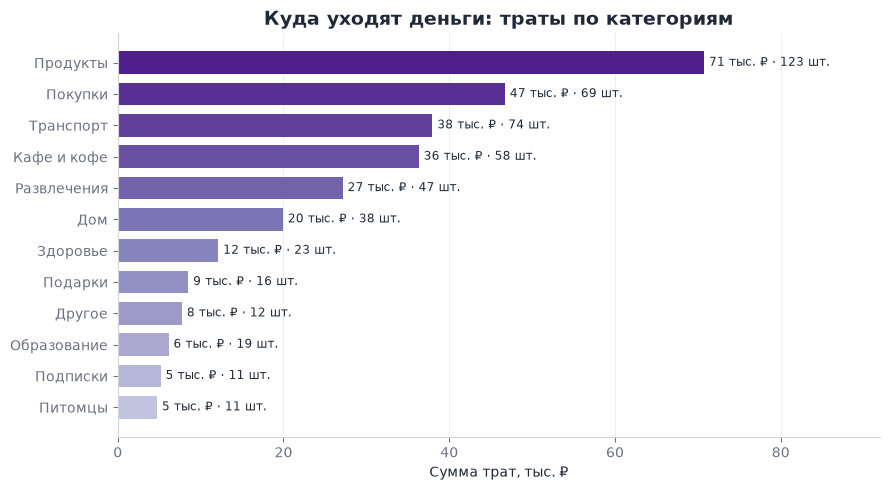

In [9]:
category = (
    tx.groupby("category_name")
    .agg(tx_count=("tx_id", "count"), total=("amount", "sum"), mean=("amount", "mean"))
    .sort_values("total", ascending=False)
)
category["share"] = category["total"] / tx["amount"].sum()

category_display = pd.DataFrame({
    "Категория": category.index,
    "Трат": category["tx_count"].map(fmt_int),
    "Сумма": category["total"].map(fmt_money),
    "Средний чек": category["mean"].map(fmt_money),
    "Доля суммы": category["share"].map(fmt_pct),
}).reset_index(drop=True)
display(category_display)

plot_data = category.sort_values("total")
fig, ax = plt.subplots(figsize=(9, 5))
colors = plt.cm.Purples(np.linspace(0.35, 0.9, len(plot_data)))
bars = ax.barh(plot_data.index, plot_data["total"] / 1000, color=colors, height=0.72)
for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(
        bar.get_width() + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{row['total'] / 1000:.0f} тыс. ₽ · {fmt_int(row['tx_count'])} шт.",
        va="center", fontsize=8.5, color="#1f2937",
    )
ax.set_xlim(0, plot_data["total"].max() / 1000 * 1.3)
ax.set_xlabel("Сумма трат, тыс. ₽")
ax.set_title("Куда уходят деньги: траты по категориям")
ax.grid(axis="x", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 5.2 Энергия бюджета по дням

Энергия — это процент потраченного дневного лимита. Выше 100% — перерасход. Дни без записей не соединяем линией, иначе график показывал бы ложные провалы до нуля.

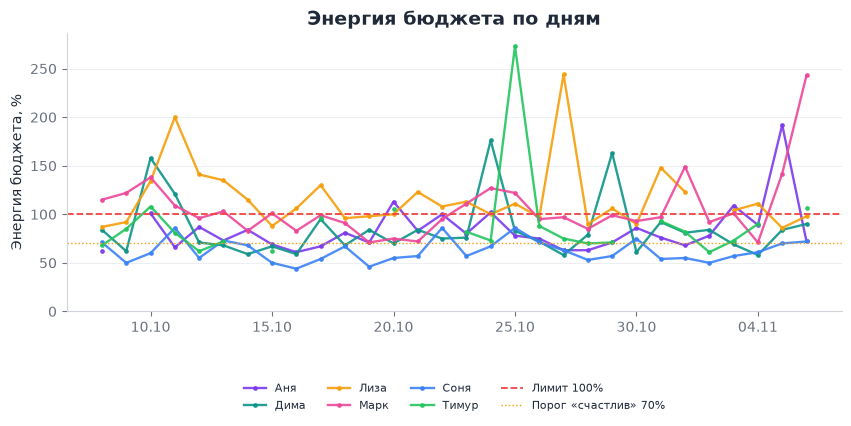

In [10]:
pivot = daily.pivot_table(index="date", columns="name", values="energy", aggfunc="first")
activity = daily.pivot_table(index="date", columns="name", values="txCount", aggfunc="first")
pivot = pivot.mask(activity.fillna(0) == 0)

user_colors = [VIOLET, TEAL, AMBER, PINK, "#3b82f6", "#22c55e"]

fig, ax = plt.subplots(figsize=(10, 4.8))
for color, column in zip(user_colors, pivot.columns):
    ax.plot(pivot.index, pivot[column], color=color, lw=1.7, marker="o", ms=2.4, alpha=0.9, label=column)

ax.axhline(100, color=RED, lw=1.3, ls="--", label="Лимит 100%")
ax.axhline(70, color=AMBER, lw=1.0, ls=":", label="Порог «счастлив» 70%")
ax.set_ylim(0, max(130, np.nanmax(pivot.values) * 1.05))
ax.set_ylabel("Энергия бюджета, %")
ax.set_title("Энергия бюджета по дням")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax.grid(axis="y", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(bottom=0.3)
plt.show()

### 5.3 Траты против лимита

Каждая точка — один активный день. Ниже пунктирной линии — день в лимите, выше — перерасход. Размер точки — число трат за день.

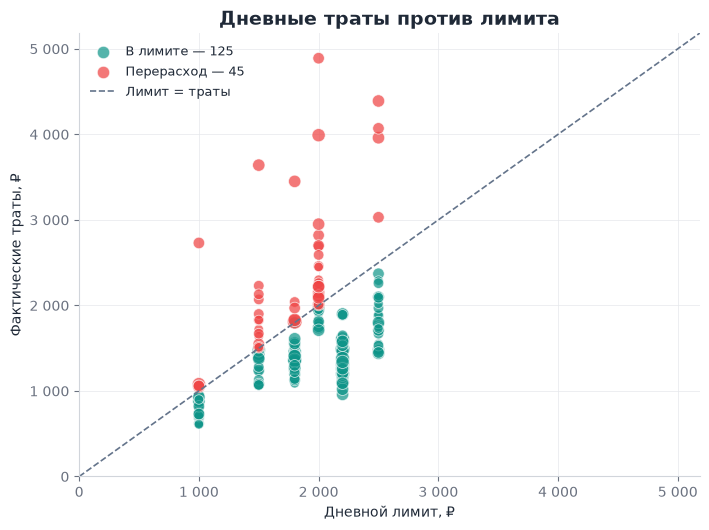

In [11]:
active = daily[daily["txCount"] > 0].copy()
within = active["withinLimit"]
over = ~within

fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.scatter(
    active.loc[within, "limit"], active.loc[within, "spent"],
    s=36 + active.loc[within, "txCount"] * 11, color=TEAL, alpha=0.7,
    edgecolor="white", linewidth=0.6, label=f"В лимите — {int(within.sum())}",
)
ax.scatter(
    active.loc[over, "limit"], active.loc[over, "spent"],
    s=36 + active.loc[over, "txCount"] * 11, color=RED, alpha=0.72,
    edgecolor="white", linewidth=0.6, label=f"Перерасход — {int(over.sum())}",
)
max_value = max(active["limit"].max(), active["spent"].max()) * 1.06
ax.plot([0, max_value], [0, max_value], color="#64748b", lw=1.2, ls="--", label="Лимит = траты")
ax.set_xlim(0, max_value)
ax.set_ylim(0, max_value)
ax.set_xlabel("Дневной лимит, ₽")
ax.set_ylabel("Фактические траты, ₽")
ax.set_title("Дневные траты против лимита")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: fmt_int(x)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: fmt_int(x)))
plt.tight_layout()
plt.show()

### 5.4 Структура трат по архетипам

Тепловая карта показывает не абсолютные суммы, а доли внутри каждого архетипа. Так честнее сравнивать: у всех разный дневной лимит и разная сумма трат.

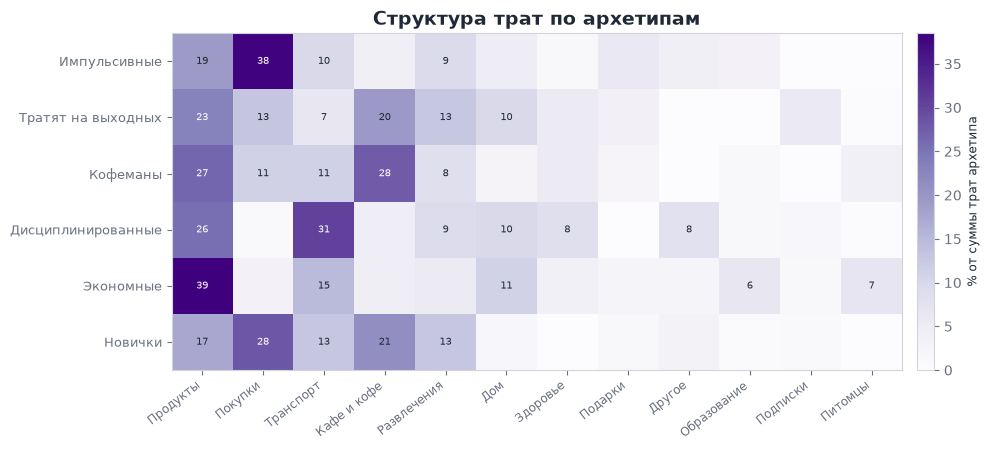

In [12]:
mix = tx.pivot_table(
    index="archetypeLabel", columns="category_name", values="amount",
    aggfunc="sum", fill_value=0,
)
mix = mix.loc[mix.sum(axis=1).sort_values(ascending=False).index]
mix = mix[mix.sum(axis=0).sort_values(ascending=False).index]
share_matrix = mix.div(mix.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(share_matrix.values, aspect="auto", cmap="Purples", vmin=0, vmax=max(35, share_matrix.values.max()))
ax.set_xticks(range(len(share_matrix.columns)))
ax.set_xticklabels(share_matrix.columns, rotation=38, ha="right", fontsize=8.5)
ax.set_yticks(range(len(share_matrix.index)))
ax.set_yticklabels(share_matrix.index, fontsize=9)

for i in range(share_matrix.shape[0]):
    for j in range(share_matrix.shape[1]):
        value = share_matrix.values[i, j]
        if value >= 6:
            color = "white" if value > 22 else "#1f2937"
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=7.5, color=color)

cbar = fig.colorbar(im, ax=ax, fraction=0.026, pad=0.02)
cbar.set_label("% от суммы трат архетипа", fontsize=8.5)
ax.set_title("Структура трат по архетипам")
plt.tight_layout()
plt.show()

## 6. Игровая экономика

### 6.1 Из чего складывается доход питомца

Монеты приходят из четырёх источников: работа, квесты, остаток энергии и недельный бонус. Посмотрим средний вклад каждого источника по архетипам.

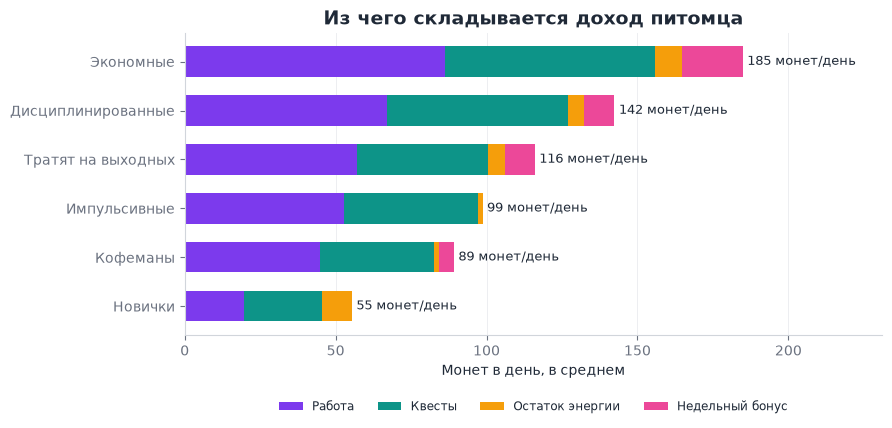

In [13]:
source_cols = ["coinsWork", "coinsQuests", "coinsLeftover", "coinsWeeklyBonus"]
source_labels = ["Работа", "Квесты", "Остаток энергии", "Недельный бонус"]
source_colors = [VIOLET, TEAL, AMBER, PINK]

source = daily.groupby("archetypeLabel")[source_cols].sum()
source = source.div(daily.groupby("archetypeLabel").size(), axis=0)
source["total"] = source.sum(axis=1)
source = source.sort_values("total")

fig, ax = plt.subplots(figsize=(9, 4.8))
left = np.zeros(len(source))
for col, label, color in zip(source_cols, source_labels, source_colors):
    values = source[col].values
    ax.barh(source.index, values, left=left, color=color, height=0.62, label=label)
    left += values

for i, (_, row) in enumerate(source.iterrows()):
    ax.text(row["total"] + 1.5, i, f"{fmt_int(row['total'])} монет/день", va="center", fontsize=9, color="#1f2937")

ax.set_xlim(0, source["total"].max() * 1.25)
ax.set_xlabel("Монет в день, в среднем")
ax.set_title("Из чего складывается доход питомца")
ax.legend(ncol=4, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(axis="x", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(bottom=0.25)
plt.show()

### 6.2 Квесты

Всего 540 попыток квестов за 30 дней. Посмотрим, какие квесты выполняются чаще, а какие — почти никогда. Для квестов, которые выпадали меньше 10 раз, процент менее надёжен, поэтому на графике оставляем только `n ≥ 10`.

,Квест,Выпадал,Выполнен,Доля
0,Итоги недели,1,1,"100,0%"
1,Одна смена,50,46,"92,0%"
2,Две смены,28,21,"75,0%"
3,Проверь питомца,49,34,"69,4%"
4,Без импульсов,19,13,"68,4%"
5,Без кофе с собой,31,19,"61,3%"
6,Уложись в лимит,64,38,"59,4%"
7,Дневник дня,48,27,"56,2%"
8,Ранняя запись,25,11,"44,0%"
9,Кофейный чек,29,10,"34,5%"


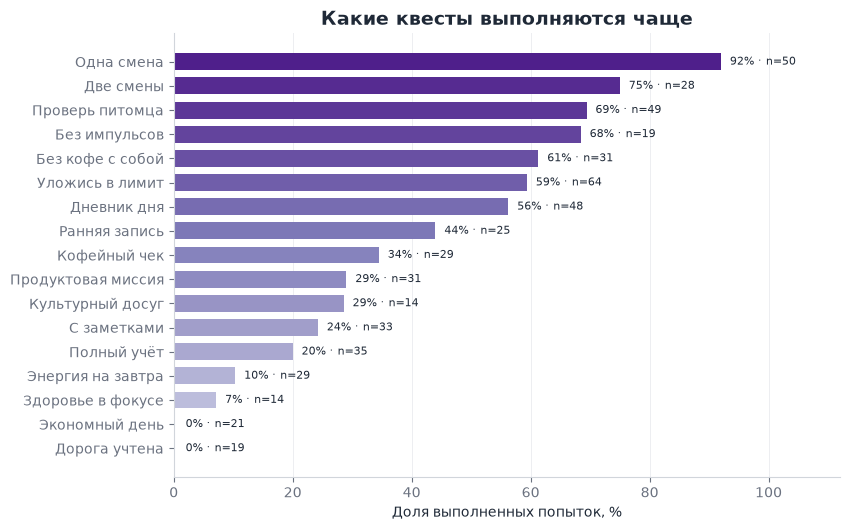

In [14]:
quest_stats = (
    quests.groupby("quest_title")
    .agg(attempts=("done", "size"), done=("done", "sum"))
)
quest_stats["rate"] = quest_stats["done"] / quest_stats["attempts"]
quest_stats = quest_stats.sort_values("rate", ascending=False)

quest_display = pd.DataFrame({
    "Квест": quest_stats.index,
    "Выпадал": quest_stats["attempts"].map(fmt_int),
    "Выполнен": quest_stats["done"].map(fmt_int),
    "Доля": quest_stats["rate"].map(fmt_pct),
}).reset_index(drop=True)
display(quest_display)

plot_quests = quest_stats[quest_stats["attempts"] >= 10].sort_values("rate")
fig, ax = plt.subplots(figsize=(8.6, 5.4))
colors = plt.cm.Purples(np.linspace(0.3, 0.9, len(plot_quests)))
bars = ax.barh(plot_quests.index, plot_quests["rate"] * 100, color=colors, height=0.7)
for bar, (_, row) in zip(bars, plot_quests.iterrows()):
    ax.text(
        max(row["rate"] * 100 + 1.5, 2),
        bar.get_y() + bar.get_height() / 2,
        f"{row['rate'] * 100:.0f}% · n={int(row['attempts'])}",
        va="center", fontsize=8, color="#1f2937",
    )
ax.set_xlim(0, 112)
ax.set_xlabel("Доля выполненных попыток, %")
ax.set_title("Какие квесты выполняются чаще")
ax.grid(axis="x", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Что видно.** Простые действия выполняются часто: «Одна смена» — 92%, «Две смены» — 75%, «Проверь питомца» — 69%. А «Экономный день» и «Дорога учтена» не выполнены ни разу за 30 дней. Это сигнал пересмотреть условия или награду, а не вина игрока.

## 7. Симуляция баланса: 400 игроков × 90 дней

Симуляция — это не реальные люди. Это способ проверить, как математика игры ведёт себя на разных стилях поведения. 400 прогонов помогают увидеть не только среднее, но и разброс.

### 7.1 Перцентили

Перцентиль показывает, какая доля прогонов оказалась ниже значения. Например, p10 — результат «слабого» прогона, p50 — медиана, p90 — результат «сильного» прогона.

In [15]:
metric_defs = [
    ("avgDailyCoins", "Монет в день", "int"),
    ("avgDailyXp", "XP в день", "int"),
    ("levelDay30", "Уровень к 30-му дню", "level"),
    ("finalLevel", "Уровень к 90-му дню", "level"),
    ("withinShare", "Доля дней в лимите", "share"),
    ("bestLogStreak", "Лучший стрик учёта", "int"),
    ("bestBudgetStreak", "Лучший бюджетный стрик", "int"),
    ("coreDays", "Дней до ядра косметики", "int"),
    ("fullDays", "Дней до полной коллекции", "int"),
    ("health", "Здоровье питомца", "int"),
]

def fmt_by_kind(value, kind):
    if kind == "share":
        return fmt_pct(value)
    if kind == "level":
        return f"{value:.1f}".replace(".", ",")
    return fmt_int(value)

percentile_rows = []
for col, label, kind in metric_defs:
    p10, p50, p90 = np.percentile(balance[col], [10, 50, 90])
    percentile_rows.append({
        "Метрика": label,
        "p10": fmt_by_kind(p10, kind),
        "p50 (медиана)": fmt_by_kind(p50, kind),
        "p90": fmt_by_kind(p90, kind),
    })

display(pd.DataFrame(percentile_rows))

,Метрика,p10,p50 (медиана),p90
0,Монет в день,73,117,177
1,XP в день,44,61,97
2,Уровень к 30-му дню,"8,0","11,0","14,0"
3,Уровень к 90-му дню,"13,0","16,0","19,0"
4,Доля дней в лимите,"32,5%","78,5%","96,6%"
5,Лучший стрик учёта,23,56,94
6,Лучший бюджетный стрик,4,11,41
7,Дней до ядра косметики,23,34,55
8,Дней до полной коллекции,84,128,205
9,Здоровье питомца,16,100,100


### 7.2 Проверка целевых коридоров

В конфиге игры заданы целевые диапазоны. Проверяем, попала ли медиана в каждый коридор и какая доля отдельных прогонов оказалась внутри.

In [16]:
corridor_defs = [
    ("avgDailyCoins", "Средние монеты в день", "int"),
    ("daysToCoreCosmetics", "Дней до ядра косметики", "int"),
    ("daysToFullCollection", "Дней до полной коллекции", "int"),
    ("overspendDaysShare", "Доля дней с перерасходом", "share"),
    ("day30Level", "Уровень к 30-му дню", "level"),
]

series_map = {
    "avgDailyCoins": balance["avgDailyCoins"],
    "daysToCoreCosmetics": balance["coreDays"],
    "daysToFullCollection": balance["fullDays"],
    "overspendDaysShare": 1 - balance["withinShare"],
    "day30Level": balance["levelDay30"],
}

corridor_rows = []
for key, label, kind in corridor_defs:
    low, high = targets[key]
    series = series_map[key]
    actual = series.median()
    inside = float(((series >= low) & (series <= high)).mean())
    corridor_rows.append({
        "Цель": label,
        "Коридор": f"{fmt_by_kind(low, kind)}–{fmt_by_kind(high, kind)}",
        "Факт (медиана)": fmt_by_kind(actual, kind),
        "Попала?": "да" if low <= actual <= high else "нет",
        "Доля прогонов внутри": fmt_pct(inside, 0),
    })

display(pd.DataFrame(corridor_rows))

,Цель,Коридор,Факт (медиана),Попала?,Доля прогонов внутри
0,Средние монеты в день,90–160,117,да,70%
1,Дней до ядра косметики,18–35,34,да,52%
2,Дней до полной коллекции,90–150,128,да,54%
3,Доля дней с перерасходом,"15,0%–35,0%","21,5%",да,25%
4,Уровень к 30-му дню,"9,0–14,0","11,0",да,82%


### 7.3 Разброс результатов

Гистограммы показывают, что «средний игрок» — это упрощение: даже в одной модели результаты сильно различаются.

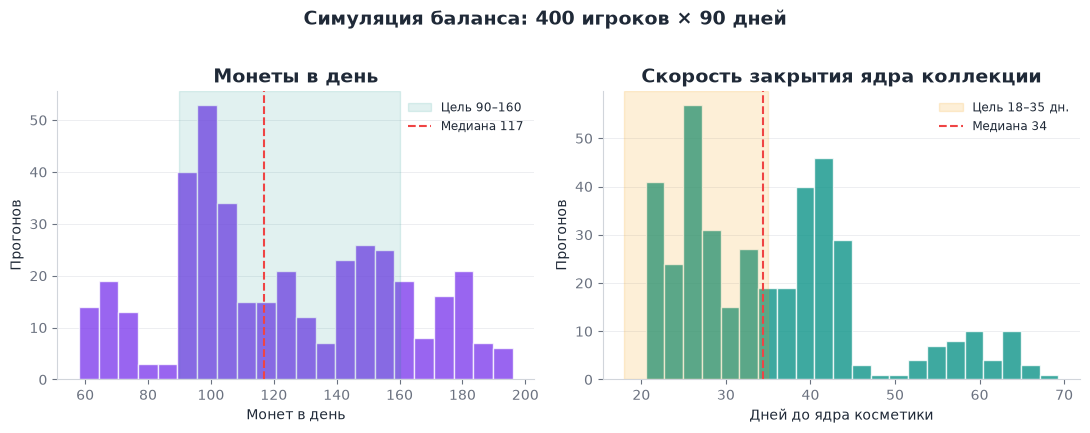

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
values = balance["avgDailyCoins"]
ax.hist(values, bins=22, color=VIOLET, alpha=0.78, edgecolor="white")
ax.axvspan(*targets["avgDailyCoins"], color=TEAL, alpha=0.12, label="Цель 90–160")
ax.axvline(values.median(), color=RED, lw=1.5, ls="--", label=f"Медиана {values.median():.0f}")
ax.set_xlabel("Монет в день")
ax.set_ylabel("Прогонов")
ax.set_title("Монеты в день")
ax.legend(fontsize=8.5)
ax.grid(axis="y", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
values = balance["coreDays"]
ax.hist(values, bins=22, color=TEAL, alpha=0.8, edgecolor="white")
ax.axvspan(*targets["daysToCoreCosmetics"], color=AMBER, alpha=0.16, label="Цель 18–35 дн.")
ax.axvline(values.median(), color=RED, lw=1.5, ls="--", label=f"Медиана {values.median():.0f}")
ax.set_xlabel("Дней до ядра косметики")
ax.set_ylabel("Прогонов")
ax.set_title("Скорость закрытия ядра коллекции")
ax.legend(fontsize=8.5)
ax.grid(axis="y", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Симуляция баланса: 400 игроков × 90 дней", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 7.4 Прогресс уровня по архетипам

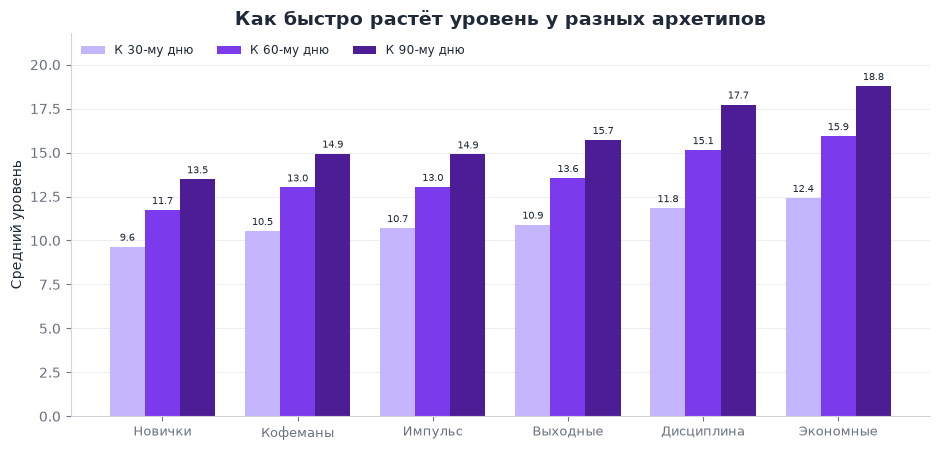

In [18]:
level_cols = ["levelDay30", "levelDay60", "finalLevel"]
level_labels = ["К 30-му дню", "К 60-му дню", "К 90-му дню"]
level_colors = ["#c4b5fd", VIOLET, "#4c1d95"]

short_names = {
    "Дисциплинированные": "Дисциплина",
    "Тратят на выходных": "Выходные",
    "Импульсивные": "Импульс",
    "Экономные": "Экономные",
    "Кофеманы": "Кофеманы",
    "Новички": "Новички",
}

level_agg = balance.groupby("archetypeLabel")[level_cols].mean().sort_values("levelDay30")
level_agg.index = [short_names.get(x, x) for x in level_agg.index]

fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = np.arange(len(level_agg))
width = 0.26
for i, (col, label, color) in enumerate(zip(level_cols, level_labels, level_colors)):
    positions = x + (i - 1) * width
    bars = ax.bar(positions, level_agg[col], width=width, color=color, label=label)
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
            f"{bar.get_height():.1f}", ha="center", va="bottom", fontsize=7.5,
        )

ax.set_xticks(x)
ax.set_xticklabels(level_agg.index, fontsize=9)
ax.set_ylabel("Средний уровень")
ax.set_ylim(0, level_agg.max().max() + 3)
ax.set_title("Как быстро растёт уровень у разных архетипов")
ax.legend(ncol=3, fontsize=8.5, loc="upper left")
ax.grid(axis="y", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 7.5 Сводка по архетипам и корреляции

In [19]:
by_archetype = (
    balance.groupby("archetypeLabel")
    .agg(
        runs=("archetype", "size"),
        coins=("avgDailyCoins", "mean"),
        xp=("avgDailyXp", "mean"),
        level30=("levelDay30", "mean"),
        within=("withinShare", "mean"),
        core_days=("coreDays", "mean"),
        health=("health", "mean"),
    )
    .sort_values("coins", ascending=False)
    .reset_index()
)

by_archetype_display = pd.DataFrame({
    "Архетип": by_archetype["archetypeLabel"],
    "Монет/день": by_archetype["coins"].map(fmt_int),
    "XP/день": by_archetype["xp"].map(fmt_int),
    "Уровень к 30-му": by_archetype["level30"].map(lambda v: f"{v:.1f}".replace(".", ",")),
    "Дней в лимите": by_archetype["within"].map(fmt_pct),
    "Дней до ядра": by_archetype["core_days"].map(fmt_int),
    "Здоровье": by_archetype["health"].map(fmt_int),
})
display(by_archetype_display)

corr = pd.DataFrame([
    {"Пара": "Дисциплина ↔ монеты", "r": balance["withinShare"].corr(balance["avgDailyCoins"])},
    {"Пара": "Дисциплина ↔ здоровье", "r": balance["withinShare"].corr(balance["health"])},
    {"Пара": "Монеты ↔ уровень к 30-му дню", "r": balance["avgDailyCoins"].corr(balance["levelDay30"])},
    {"Пара": "Монеты ↔ здоровье", "r": balance["avgDailyCoins"].corr(balance["health"])},
])
corr["r"] = corr["r"].map(lambda v: f"{v:+.2f}".replace(".", ","))
display(corr)

,Архетип,Монет/день,XP/день,Уровень к 30-му,Дней в лимите,Дней до ядра,Здоровье
0,Экономные,178,98,"12,4","97,7%",23,99
1,Дисциплинированные,151,86,"11,8","91,2%",27,99
2,Тратят на выходных,121,63,"10,9","79,4%",33,98
3,Кофеманы,99,54,"10,5","51,3%",41,82
4,Импульсивные,98,52,"10,7","31,8%",41,17
5,Новички,68,41,"9,6","69,9%",59,96


,Пара,r
0,Дисциплина ↔ монеты,"+0,73"
1,Дисциплина ↔ здоровье,"+0,83"
2,Монеты ↔ уровень к 30-му дню,"+0,47"
3,Монеты ↔ здоровье,"+0,40"


**Как читать корреляцию.** Коэффициент `r` от −1 до +1. Чем ближе к +1, тем сильнее две метрики растут вместе. Но это **не доказательство причины и следствия**. В нашей модели дисциплина напрямую увеличивает монеты и здоровье, поэтому связь ожидаема. На реальных людях такая корреляция могла бы объясняться третьим фактором, например доходом.

## 8. Главные выводы

- В `MOCK_DATA` 1 000 пользователей, из них **515 (51,5%)** помечены как использующие FinApp. Это доля внутри файла, а не оценка рынка.
- В игровом наборе **501 трата на 283 260 ₽**. Средний чек **565 ₽**, медианный — **410 ₽**: распределение смещено крупными покупками.
- Крупнейшие категории: продукты (70 750 ₽), покупки (46 720 ₽), транспорт (37 960 ₽), кафе (36 320 ₽).
- Из **170 активных дней 125 (73,5%)** уложились в лимит, **45** — с перерасходом. Ещё **10 дней** остались без записей.
- В симуляции медиана дохода — **117 монет в день**, **11-й уровень** к 30-му дню, **16-й** — к 90-му. Ядро косметики закрывается примерно за **34 дня**, полная коллекция — примерно за **128**.
- Квесты: выполнено **252 из 540** попыток. «Экономный день» и «Дорога учтена» не выполнены ни разу — это повод пересмотреть условия, а не вина игрока.
- Корреляции (дисциплина ↔ монеты +0,73, дисциплина ↔ здоровье +0,83) — следствие заложенных формул, а не доказательство причинности.

**Итог одной фразой.** Данные прототипа показывают, что игровая петля собирает траты, дисциплину, награды и прогресс в одну систему; `MOCK_DATA` показывает только демографическую заглушку. Сильнее всего анализ улучшит не новый график, а связка данных по пользователю и событиям.

## 9. Ограничения анализа

- **Синтетика.** Все игровые пользователи и траты сгенерированы по правилам, а не собраны с людей.
- **Маленькая выборка.** 6 игровых пользователей и 30 дней не дают статистической значимости.
- **Нет причинности.** Корреляции в симуляции — следствие заложенных формул.
- **`MOCK_DATA` не про финансы.** Там нет сумм, категорий и дат.
- **Наборы не связаны.** Нельзя утверждать, что 51,5% из `MOCK_DATA` — это аудитория игры.
- **Средние обманчивы.** Поэтому в анализе есть медианы, перцентили и разброс.

### Что бы я добавил, чтобы анализ стал сильнее

1. Единый `user_id` во всех таблицах.
2. Даты и события продукта в `MOCK_DATA`.
3. Реальные или хотя бы правдоподобные транзакции вместо одного флага.
4. Когорты, канал привлечения и A/B-тесты.
5. Больше игровых пользователей и более длинный горизонт.

## 10. Как воспроизвести

Из корня репозитория:

```powershell
python -m pip install -r analysis/requirements.txt
python analysis/analyze.py
```

Скрипт `analysis/analyze.py` пересобирает графики, CSV, `report.md` и `dashboard.html`. Этот ноутбук использует те же данные и те же принципы, но показывает их пошагово — его удобно открыть в Google Colab и нажать **Runtime → Run all**.

**Ссылки:**

- Репозиторий: <https://github.com/Ferlios/FinGame>
- Отчёт в Markdown: <https://github.com/Ferlios/FinGame/blob/main/analysis/report.md>
- Дашборд: <https://github.com/Ferlios/FinGame/blob/main/analysis/dashboard.html>
- Этот ноутбук в Colab: <https://colab.research.google.com/github/Ferlios/FinGame/blob/main/analysis/FinGame_analysis.ipynb>

> Все данные синтетические. Это учебный анализ, а не исследование реальных людей и не финансовый совет.